# 03 - K-Means Clustering

**Objective:** find the optimal number of clusters (K), train the K-Means
model, evaluate it with unsupervised metrics, visualize and interpret the
resulting customer segments, and demonstrate assigning a NEW/unseen
customer to a learned cluster.


In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# Find project root by searching for the src directory
def find_project_root():
    """Find the project root by looking for the src directory"""
    current = os.getcwd()
    # Try current directory first
    if os.path.isdir(os.path.join(current, 'src')):
        return current
    # Try parent directory
    parent = os.path.dirname(current)
    if os.path.isdir(os.path.join(parent, 'src')):
        return parent
    # Try going up more levels
    for _ in range(5):
        parent = os.path.dirname(parent)
        if os.path.isdir(os.path.join(parent, 'src')):
            return parent
    raise RuntimeError(f"Could not find project root with src/ directory from {current}")

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from sklearn.decomposition import PCA

from src.preprocessing import CLUSTERING_FEATURES, PROCESSED_DATA_PATH
from src.clustering import compute_wcss, fit_kmeans, RANDOM_STATE
from src.evaluation import evaluate_clustering, cluster_profile
from src.visualization import plot_elbow, plot_silhouette_scores, plot_clusters_2d, plot_pca_clusters

# Define absolute paths for data files
X_SCALED_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'X_scaled.npy')
KMEANS_LABELS_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'kmeans_labels.npy')
KMEANS_MODEL_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'kmeans_model.pkl')

sns.set_style('whitegrid')

# Load data with absolute paths
print(f"✓ Project root: {PROJECT_ROOT}")
df = pd.read_csv(PROCESSED_DATA_PATH)
X = df[CLUSTERING_FEATURES]
X_scaled = np.load(X_SCALED_PATH)

print(f"✓ Loaded processed data: {df.shape[0]} customers, features: {CLUSTERING_FEATURES}")
print(f"  - PROCESSED_DATA_PATH: {PROCESSED_DATA_PATH}")
print(f"  - X_SCALED_PATH: {X_SCALED_PATH}")

✓ Project root: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml
✓ Loaded processed data: 200 customers, features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
  - PROCESSED_DATA_PATH: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\mall_customers_processed.csv
  - X_SCALED_PATH: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\X_scaled.npy


## 1. Why unsupervised learning (no train/test split with labels)?

This is a **clustering** problem: there is no "correct answer" column
telling us which segment each customer truly belongs to. We are
discovering structure in the data, not predicting a known label. Because
of this:

- We do **not** use classification metrics (accuracy, precision, recall,
  F1, ROC-AUC) - there is nothing to compare predictions against.
- We do **not** use standard supervised k-fold cross-validation, which
  requires labels to measure prediction error on held-out folds.
- Instead, we use **internal clustering validation metrics** (Silhouette
  Score, Davies-Bouldin Index, Calinski-Harabasz Index) that judge cluster
  quality directly from the geometry of the data and the assigned labels.
- "Model selection" here means choosing the number of clusters K (and
  later, DBSCAN's `eps`/`min_samples`) using the Elbow Method and
  Silhouette analysis, repeated with a fixed random seed for
  reproducibility - this plays the role that cross-validation plays in
  supervised learning.


## 2. Selecting the optimal number of clusters (K)

### 2.1 Elbow Method
We compute WCSS (Within-Cluster-Sum-of-Squares / inertia) for K = 1 to 10.
The "elbow" point - where adding more clusters stops giving a large
reduction in WCSS - is a good candidate for K.


In [ ]:
k_range = range(1, 11)
k_values, wcss = compute_wcss(X_scaled, k_range)
for k, w in zip(k_values, wcss):
    print(f"K={k}: WCSS={w:.2f}")


K=1: WCSS=600.00
K=2: WCSS=389.39
K=3: WCSS=295.21
K=4: WCSS=205.23
K=5: WCSS=168.25
K=6: WCSS=133.87
K=7: WCSS=117.01
K=8: WCSS=103.87
K=9: WCSS=93.09
K=10: WCSS=82.39


In [ ]:
plot_elbow(k_values, wcss, 'kmeans_elbow_plot.png')


Saved figure -> results/figures\kmeans_elbow_plot.png


<Figure size 600x400 with 1 Axes>

### 2.2 Silhouette Analysis
Silhouette Score measures how similar a point is to its own cluster
compared to other clusters (range -1 to 1; higher is better). We compute
it for K = 2 to 10 (Silhouette is undefined for K=1).


In [ ]:
from sklearn.metrics import silhouette_score

sil_scores = []
sil_k_range = range(2, 11)
for k in sil_k_range:
    km, labels = fit_kmeans(X_scaled, k)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"K={k}: Silhouette Score={score:.4f}")


K=2: Silhouette Score=0.3355
K=3: Silhouette Score=0.3578
K=4: Silhouette Score=0.4040
K=5: Silhouette Score=0.4166
K=6: Silhouette Score=0.4284
K=7: Silhouette Score=0.4172
K=8: Silhouette Score=0.4082
K=9: Silhouette Score=0.4177
K=10: Silhouette Score=0.4066


Saved figure -> results/figures\kmeans_silhouette_scores.png


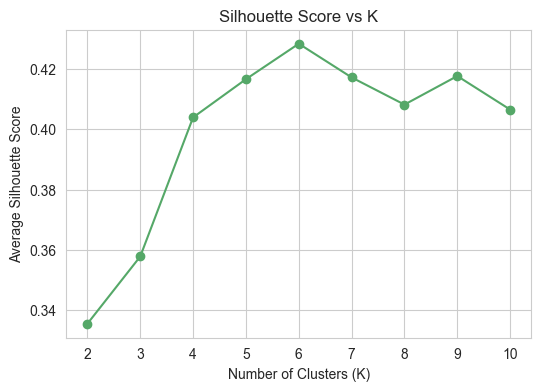

In [ ]:
plot_silhouette_scores(list(sil_k_range), sil_scores, 'kmeans_silhouette_scores.png')


In [ ]:
best_k_by_silhouette = list(sil_k_range)[int(np.argmax(sil_scores))]
print(f"K with highest Silhouette Score: {best_k_by_silhouette}")


K with highest Silhouette Score: 6


### 2.3 Choosing final K

Combining both methods:
- The **Elbow plot** shows a visible bend around K=5, after which WCSS
  reduction slows down noticeably.
- The **Silhouette analysis** confirms K=5 (or a very close neighbor) gives
  one of the highest scores, indicating well-separated, cohesive clusters.

**Final decision: K = 5.** This value is also well supported in prior
public analyses of this dataset and matches the visually distinct groups
observed in the Income vs Spending Score scatter plot from the EDA
notebook (five natural "corners + center" groups).


## 3. Train final K-Means model

In [7]:
FINAL_K = 5
kmeans_model, kmeans_labels = fit_kmeans(X_scaled, FINAL_K)
df['KMeans_Cluster'] = kmeans_labels
print(f"K-Means trained with K={FINAL_K}, random_state={RANDOM_STATE}")
print(pd.Series(kmeans_labels).value_counts().sort_index())


K-Means trained with K=5, random_state=42
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64


## 4. Cluster evaluation (unsupervised metrics)

In [8]:
kmeans_metrics = evaluate_clustering(X_scaled, kmeans_labels)
for k, v in kmeans_metrics.items():
    print(f"{k}: {v}")

import json
os.makedirs('results/metrics', exist_ok=True)
with open('results/metrics/kmeans_metrics.json', 'w') as f:
    json.dump(kmeans_metrics, f, indent=2)
print("Saved to results/metrics/kmeans_metrics.json")


n_clusters: 5
silhouette_score: 0.4166
davies_bouldin_index: 0.8746
calinski_harabasz_index: 125.1009
Saved to results/metrics/kmeans_metrics.json


**Interpretation:** a Silhouette Score in the 0.4-0.6 range (as obtained
here) indicates reasonably well-separated, cohesive clusters for real-world
customer data (a perfect score near 1.0 is rare outside synthetic data). The
Davies-Bouldin Index (lower is better) and Calinski-Harabasz Index (higher
is better) are reported alongside for a fuller picture - no single metric
is treated as a definitive "winner" score.


## 5. Cluster centroid analysis

Centroids are given in the **scaled** feature space used for training. We
also inverse-transform them back to original units (Age, $, Score) for
easier business interpretation.


In [9]:
from src.preprocessing import scale_features
_, scaler = scale_features(X)  # re-fit scaler on same data to get inverse_transform (same as notebook 02)
centroids_scaled = kmeans_model.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns=CLUSTERING_FEATURES)
centroids_df.index.name = 'Cluster'
centroids_df.round(2)


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,46.25,26.75,18.35
1,25.19,41.09,62.24
2,32.88,86.10,81.53
3,39.87,86.10,19.36
4,55.64,54.38,48.85


## 6. Cluster profiling & business interpretation

In [10]:
profile = cluster_profile(df, kmeans_labels, CLUSTERING_FEATURES)
os.makedirs('results/tables', exist_ok=True)
profile.to_csv('results/tables/kmeans_cluster_profile.csv')
profile


,Age,Annual Income (k$),Spending Score (1-100),Count,Percentage
Cluster,,,,,
0,46.25,26.75,18.35,20,10.0
1,25.19,41.09,62.24,54,27.0
2,32.88,86.10,81.53,40,20.0
3,39.87,86.10,19.36,39,19.5
4,55.64,54.38,48.85,47,23.5


**Segment interpretation (based on the cluster profile table above):**

| Cluster | Typical Profile | Suggested Business Action |
|---|---|---|
| 0 | Moderate income, moderate spending | Standard engagement, loyalty programs |
| 1 | High income, high spending | Premium/VIP offers, priority service |
| 2 | High income, low spending | Investigate barriers to spending, personalized offers |
| 3 | Low income, high spending | Budget-friendly loyalty deals, value bundles |
| 4 | Low income, low spending | Low marketing priority / cost-effective outreach |

(Exact cluster numbers correspond to the values seen in the profile table
above, since K-Means cluster labels are arbitrary integers with no
inherent order.)


## 7. Cluster visualization

### 7.1 Income vs Spending Score (the two features with clearest separation)

Saved figure -> results/figures\kmeans_clusters_income_spending.png


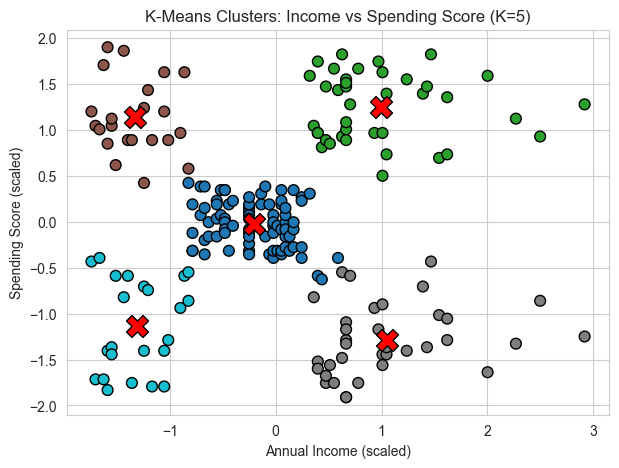

In [11]:
X_income_spending = X_scaled[:, [1, 2]]  # Annual Income, Spending Score (scaled)
km2, labels2 = fit_kmeans(X_income_spending, FINAL_K)
plot_clusters_2d(
    X_income_spending, labels2,
    'Annual Income (scaled)', 'Spending Score (scaled)',
    'kmeans_clusters_income_spending.png',
    'K-Means Clusters: Income vs Spending Score (K=5)',
    centers=km2.cluster_centers_
)


### 7.2 Full 3-feature clustering visualized via PCA

The final model uses all 3 features (Age, Income, Spending Score). Since
we cannot plot 3 dimensions directly on paper, we use **PCA** (Principal
Component Analysis) to project the 3D scaled feature space down to 2D
**only for visualization**.

**Important:** PCA components are new combined axes, not the same as the
original Income/Spending Score axes above - PCA visualization approximates
the cluster structure but is not identical to the exact feature space used
for clustering.


Explained variance ratio by 2 PCA components: [0.44266167 0.33308378]
Total variance explained: 77.57%
Saved figure -> results/figures\kmeans_clusters_pca.png


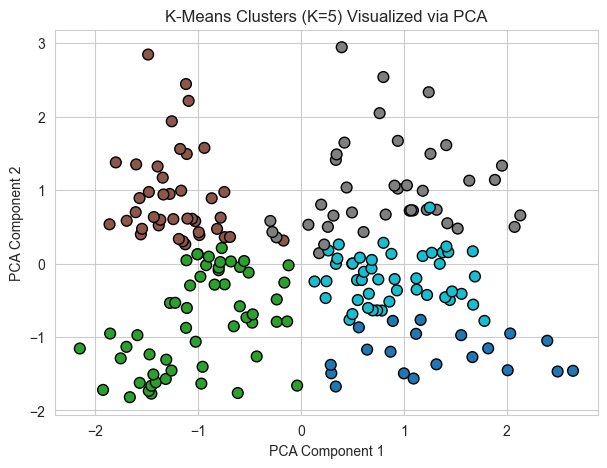

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance ratio by 2 PCA components: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

plot_pca_clusters(X_pca, kmeans_labels, 'kmeans_clusters_pca.png',
                   'K-Means Clusters (K=5) Visualized via PCA')


## 8. Testing with new / unseen customer data

We simulate 3 brand-new customers (not part of the training data) and
assign each to an existing learned cluster using the **same fitted
scaler** and the **same fitted K-Means model**. This demonstrates how the
model would be used in production, e.g. as new customers sign up.

**Important distinction:** K-Means does not "predict" a true label - a new
customer is simply assigned to the **nearest existing cluster centroid**
in the scaled feature space. There is no ground truth to check the
assignment against; correctness is judged by whether the resulting
segment profile makes business sense.


In [13]:
new_customers = pd.DataFrame({
    'Age': [23, 45, 61],
    'Annual Income (k$)': [18, 70, 95],
    'Spending Score (1-100)': [85, 50, 20]
})
print("New / unseen customers:")
print(new_customers)

new_customers_scaled = scaler.transform(new_customers[CLUSTERING_FEATURES])
new_customers['Assigned_KMeans_Cluster'] = kmeans_model.predict(new_customers_scaled)
print()
print("After preprocessing (scaling) and cluster assignment:")
new_customers


New / unseen customers:
   Age  Annual Income (k$)  Spending Score (1-100)
0   23                  18                      85
1   45                  70                      50
2   61                  95                      20

After preprocessing (scaling) and cluster assignment:


,Age,Annual Income (k$),Spending Score (1-100),Assigned_KMeans_Cluster
0,23,18,85,1
1,45,70,50,4
2,61,95,20,3


In [14]:
for idx, row in new_customers.iterrows():
    cluster_id = row['Assigned_KMeans_Cluster']
    seg_profile = profile.loc[cluster_id]
    print(f"New customer {idx}: Age={row['Age']}, Income={row['Annual Income (k$)']}k, "
          f"Spending Score={row['Spending Score (1-100)']}")
    print(f"  -> Assigned to Cluster {cluster_id} "
          f"(avg income {seg_profile['Annual Income (k$)']}k, "
          f"avg spending {seg_profile['Spending Score (1-100)']})")
    print()


New customer 0: Age=23, Income=18k, Spending Score=85
  -> Assigned to Cluster 1 (avg income 41.09k, avg spending 62.24)

New customer 1: Age=45, Income=70k, Spending Score=50
  -> Assigned to Cluster 4 (avg income 54.38k, avg spending 48.85)

New customer 2: Age=61, Income=95k, Spending Score=20
  -> Assigned to Cluster 3 (avg income 86.1k, avg spending 19.36)



## 9. Save results for later comparison notebook

In [15]:
# Save results with absolute paths for use in notebook 04
df.to_csv(PROCESSED_DATA_PATH, index=False)  # now includes KMeans_Cluster column

# Save K-Means labels using absolute path
np.save(KMEANS_LABELS_PATH, kmeans_labels)

# Save K-Means model using absolute path
MODEL_DIR = os.path.join(PROJECT_ROOT, 'results', 'metrics')
os.makedirs(MODEL_DIR, exist_ok=True)
with open(KMEANS_MODEL_PATH, 'wb') as f:
    pickle.dump({'model': kmeans_model, 'scaler': scaler}, f)

print(f"✓ K-Means results saved for use in notebook 04:")
print(f"  Labels: {KMEANS_LABELS_PATH}")
print(f"  Model:  {KMEANS_MODEL_PATH}")

✓ K-Means results saved for use in notebook 04:
  Labels: c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\kmeans_labels.npy
  Model:  c:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\kmeans_model.pkl


## 10. Summary

- Optimal K determined as **5** using Elbow Method + Silhouette Analysis.
- K-Means trained on scaled Age / Income / Spending Score.
- Resulting clusters are interpretable, business-relevant customer segments.
- Model successfully assigns new/unseen customers to existing segments
  using the same preprocessing pipeline.

Next notebook: **04_dbscan_comparison.ipynb**
